In [1]:
import os
import sys
import gc
import time
import math
import shutil
import warnings
import importlib
import subprocess

warnings.filterwarnings("ignore")

START_TIME = time.time()


def log(message):
    print(f"[{time.time() - START_TIME:7.1f}s] {message}", flush=True)


def pip_install(*packages):
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-q", *packages],
        stdout=subprocess.DEVNULL,
    )


def ensure_module(module_name, package_name=None):
    try:
        importlib.import_module(module_name)
        return True
    except Exception:
        pass
    try:
        pip_install(package_name or module_name)
        importlib.invalidate_caches()
        importlib.import_module(module_name)
        return True
    except Exception:
        return False


ensure_module("lightgbm")
HAS_IMPLICIT = ensure_module("implicit")

import numpy as np
import pandas as pd
import lightgbm as lgb
from scipy import sparse
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import roc_auc_score

SEED = 42
rng = np.random.RandomState(SEED)
np.random.seed(SEED)

print("Libraries ready | implicit available:", HAS_IMPLICIT)
print("LightGBM version:", lgb.__version__)

Libraries ready | implicit available: True
LightGBM version: 4.6.0


In [2]:
!pip install -q kaggle

!kaggle datasets download \
    -d basmalagamal/h-and-m-fashion-data \
    --unzip

Dataset URL: https://www.kaggle.com/datasets/basmalagamal/h-and-m-fashion-data
License(s): unknown
100% 418M/418M [00:11<00:00, 39.2MB/s]



In [3]:
import os

DATA_PATH = "/content"

files = {}

target_files = {
    "articles_sampled.csv",
    "customers_sampled.csv",
    "transactions_sampled.csv",
    "hybrid_recommendations.csv",
    "final_retrieval_comparison.csv"
}

for root, dirs, filenames in os.walk(DATA_PATH):
    for filename in filenames:
        if filename in target_files:
            files[filename] = os.path.join(root, filename)

for name in sorted(target_files):
    if name in files:
        print(name, "->", files[name])
    else:
        print(name, "-> NOT FOUND")

articles_sampled.csv -> /content/articles_sampled.csv
customers_sampled.csv -> /content/customers_sampled.csv
final_retrieval_comparison.csv -> /content/final_retrieval_comparison.csv
hybrid_recommendations.csv -> /content/hybrid_recommendations.csv
transactions_sampled.csv -> /content/transactions_sampled.csv


In [4]:
DATASET_SLUG = "basmalagamal/h-and-m-fashion-data"

WANTED = {
    "articles": ["articles_sampled.csv"],
    "customers": ["customers_sampled.csv"],
    "transactions": ["transactions_sampled.csv"],
    "candidates": ["hybrid_recommendations.csv", "hybrid_recommendations.csv.gz"],
}

SEARCH_ROOTS = ["/content", "/kaggle/input", "/kaggle/working", os.getcwd()]
MAX_DEPTH = 4


def locate_files():
    found = {}
    for root in SEARCH_ROOTS:
        if not os.path.isdir(root):
            continue
        base_depth = root.rstrip(os.sep).count(os.sep)
        for current, dirnames, filenames in os.walk(root):
            depth = current.rstrip(os.sep).count(os.sep) - base_depth
            if depth >= MAX_DEPTH:
                dirnames[:] = []
            for key, names in WANTED.items():
                if key in found:
                    continue
                for name in names:
                    if name in filenames:
                        found[key] = os.path.join(current, name)
                        break
        if len(found) == len(WANTED):
            break
    return found


paths = locate_files()

if len(paths) < len(WANTED):
    download_dir = "/content" if os.path.isdir("/content") else os.getcwd()
    if shutil.which("kaggle") is None:
        pip_install("kaggle")
    subprocess.run(
        [
            "kaggle", "datasets", "download",
            "-d", DATASET_SLUG,
            "--unzip",
            "-p", download_dir,
        ],
        check=True,
    )
    paths = locate_files()

missing = [key for key in WANTED if key not in paths]
if missing:
    raise FileNotFoundError(
        f"Could not find files for: {missing}. "
        "Add your Kaggle credentials in Colab and run this cell again."
    )

for key, value in paths.items():
    print(f"{key:13s} -> {value}")

try:
    import psutil
    TOTAL_RAM_GB = psutil.virtual_memory().total / 1e9
except Exception:
    TOTAL_RAM_GB = 12.0

RETRIEVAL_TOP = 500 if TOTAL_RAM_GB >= 24 else 300
ALS_TOP = 100
REPURCHASE_TOP = 30
FACTORS = 64
ALS_ITERATIONS = 15
ALS_ALPHA = 15.0
NEGATIVE_KEEP = 0.5
CHUNK_ROWS = 500_000
N_THREADS = os.cpu_count() or 2

print(f"RAM: {TOTAL_RAM_GB:.1f} GB | retrieval candidates used per customer: {RETRIEVAL_TOP}")

articles      -> /content/articles_sampled.csv
customers     -> /content/customers_sampled.csv
transactions  -> /content/transactions_sampled.csv
candidates    -> /content/hybrid_recommendations.csv
RAM: 13.6 GB | retrieval candidates used per customer: 300


In [5]:
CATEGORY_COLUMNS = [
    "product_code",
    "product_type_no",
    "colour_group_code",
    "department_no",
    "section_no",
    "garment_group_no",
    "graphical_appearance_no",
    "index_group_no",
]

customers = pd.read_csv(
    paths["customers"],
    usecols=lambda column: column in {
        "customer_id", "FN", "Active", "club_member_status",
        "fashion_news_frequency", "age",
    },
)
articles = pd.read_csv(
    paths["articles"],
    usecols=lambda column: column == "article_id" or column in CATEGORY_COLUMNS,
)

customers["customer_id"] = customers["customer_id"].astype(str).str.strip()
customers = customers.drop_duplicates(subset="customer_id").reset_index(drop=True)

articles["article_id"] = pd.to_numeric(articles["article_id"], errors="coerce")
articles = articles.dropna(subset=["article_id"]).copy()
articles["article_id"] = articles["article_id"].astype(np.int64)
articles = articles.drop_duplicates(subset="article_id").reset_index(drop=True)

customer_index = pd.Index(customers["customer_id"])
article_index = pd.Index(articles["article_id"])
n_users = len(customer_index)
n_items = len(article_index)


def numeric_column(frame, name, default):
    if name in frame.columns:
        return pd.to_numeric(frame[name], errors="coerce").to_numpy(dtype=np.float32)
    return np.full(len(frame), default, dtype=np.float32)


def code_column(frame, name):
    if name in frame.columns:
        return pd.factorize(frame[name].astype(str))[0].astype(np.float32)
    return np.zeros(len(frame), dtype=np.float32)


user_age = numeric_column(customers, "age", np.nan)
finite_age = np.isfinite(user_age)
age_fill = float(np.median(user_age[finite_age])) if finite_age.any() else 30.0
user_age = np.where(finite_age, user_age, age_fill).astype(np.float32)
user_fn = np.nan_to_num(numeric_column(customers, "FN", 0.0), nan=0.0)
user_active = np.nan_to_num(numeric_column(customers, "Active", 0.0), nan=0.0)
user_club = code_column(customers, "club_member_status")
user_news = code_column(customers, "fashion_news_frequency")
AGE_BINS = 8
user_age_bin = np.digitize(user_age, [20, 25, 30, 35, 40, 50, 60]).astype(np.int64)

category_codes = {}
for column_name in CATEGORY_COLUMNS:
    if column_name in articles.columns:
        category_codes[column_name] = (
            pd.factorize(articles[column_name])[0] + 1
        ).astype(np.int64)

print("Customers:", n_users, "| Articles:", n_items)
print("Article category columns used:", list(category_codes))

Customers: 1076441 | Articles: 30000
Article category columns used: ['product_code', 'product_type_no', 'colour_group_code', 'department_no', 'section_no', 'garment_group_no', 'graphical_appearance_no', 'index_group_no']


In [6]:
BASE_DATE = pd.Timestamp("2018-01-01")
TX_COLUMNS = {"t_dat", "customer_id", "article_id", "price", "sales_channel_id"}


def day_numbers(series):
    parsed = pd.to_datetime(series, errors="coerce")
    return (parsed - BASE_DATE).dt.days.to_numpy(dtype=np.float64)


tx_u, tx_a, tx_d, tx_p, tx_c = [], [], [], [], []

reader = pd.read_csv(
    paths["transactions"],
    usecols=lambda column: column in TX_COLUMNS,
    chunksize=1_000_000,
)

for chunk in reader:
    u = customer_index.get_indexer(chunk["customer_id"].astype(str).str.strip())
    a = article_index.get_indexer(
        pd.to_numeric(chunk["article_id"], errors="coerce").fillna(-1).astype(np.int64)
    )
    d = day_numbers(chunk["t_dat"])
    if "price" in chunk.columns:
        p = pd.to_numeric(chunk["price"], errors="coerce").fillna(0.0).to_numpy(dtype=np.float32)
    else:
        p = np.zeros(len(chunk), dtype=np.float32)
    if "sales_channel_id" in chunk.columns:
        c = pd.to_numeric(chunk["sales_channel_id"], errors="coerce").fillna(0).to_numpy(dtype=np.int8)
    else:
        c = np.zeros(len(chunk), dtype=np.int8)
    ok = (u >= 0) & (a >= 0) & np.isfinite(d)
    tx_u.append(u[ok].astype(np.int32))
    tx_a.append(a[ok].astype(np.int32))
    tx_d.append(d[ok].astype(np.int16))
    tx_p.append(p[ok])
    tx_c.append(c[ok])

tx_u = np.concatenate(tx_u)
tx_a = np.concatenate(tx_a)
tx_d = np.concatenate(tx_d)
tx_p = np.concatenate(tx_p)
tx_c = np.concatenate(tx_c)
gc.collect()

first_day = BASE_DATE + pd.Timedelta(days=int(tx_d.min()))
last_day = BASE_DATE + pd.Timedelta(days=int(tx_d.max()))
log(f"Transactions loaded: {len(tx_u):,} rows | {first_day.date()} -> {last_day.date()}")

[  287.5s] Transactions loaded: 8,837,417 rows | 2018-09-20 -> 2020-09-22


In [7]:
ret_keys_parts, ret_rank_parts = [], []

reader = pd.read_csv(
    paths["candidates"],
    usecols=lambda column: column in {"customer_id", "article_id", "rank"},
    chunksize=1_000_000,
)

for chunk in reader:
    u = customer_index.get_indexer(chunk["customer_id"].astype(str).str.strip())
    a = article_index.get_indexer(
        pd.to_numeric(chunk["article_id"], errors="coerce").fillna(-1).astype(np.int64)
    )
    r = pd.to_numeric(chunk["rank"], errors="coerce").fillna(10 ** 6).to_numpy(dtype=np.float64)
    ok = (u >= 0) & (a >= 0) & (r <= RETRIEVAL_TOP)
    ret_keys_parts.append(u[ok].astype(np.int64) * n_items + a[ok])
    ret_rank_parts.append(r[ok].astype(np.float32))

ret_keys = np.concatenate(ret_keys_parts)
ret_rank = np.concatenate(ret_rank_parts)
del ret_keys_parts, ret_rank_parts
gc.collect()

order = np.lexsort((ret_rank, ret_keys))
ret_keys = ret_keys[order]
ret_rank = ret_rank[order]
first_occurrence = np.concatenate(([True], ret_keys[1:] != ret_keys[:-1]))
ret_keys = ret_keys[first_occurrence]
ret_rank = ret_rank[first_occurrence]
del order, first_occurrence

log(
    f"Retrieval candidates kept: {len(ret_keys):,} rows | "
    f"customers: {len(np.unique(ret_keys // n_items)):,}"
)

[  309.8s] Retrieval candidates kept: 7,446,600 rows | customers: 24,822


In [8]:
def day_of(date_string):
    return int((pd.Timestamp(date_string) - BASE_DATE).days)


WINDOW_OPTIONS = [
    ("2020-07-01", "2020-08-01"),
    ("2020-08-01", "2020-09-01"),
    ("2020-06-01", "2020-07-01"),
    ("2020-09-01", "2020-09-23"),
    ("2020-09-16", "2020-09-23"),
    ("2020-05-01", "2020-06-01"),
]

candidate_user_mask = np.zeros(n_users, dtype=bool)
candidate_user_mask[ret_keys // n_items] = True
n_candidate_users = int(candidate_user_mask.sum())


def window_targets(start_day, end_day):
    in_window = (tx_d >= start_day) & (tx_d < end_day)
    in_window &= candidate_user_mask[tx_u]
    seen_before = np.zeros(n_items, dtype=bool)
    seen_before[tx_a[tx_d < start_day]] = True
    in_window &= seen_before[tx_a]
    keys = tx_u[in_window].astype(np.int64) * n_items + tx_a[in_window]
    return np.unique(keys)


best_window = None
for start_text, end_text in WINDOW_OPTIONS:
    start_day, end_day = day_of(start_text), day_of(end_text)
    keys = window_targets(start_day, end_day)
    coverage = len(np.unique(keys // n_items)) / max(n_candidate_users, 1)
    log(f"Window {start_text} -> {end_text}: customers with purchases = {coverage:.1%}")
    if best_window is None or coverage > best_window[0]:
        best_window = (coverage, start_day, end_day, keys, start_text, end_text)
    if coverage >= 0.9:
        break

window_coverage, CUT_DAY, WINDOW_END, target_keys, window_start_text, window_end_text = best_window

if len(target_keys) == 0:
    raise ValueError("No purchases found in any target window for the candidate customers.")

total_targets = np.bincount(target_keys // n_items, minlength=n_users)

print(f"Target window: {window_start_text} -> {window_end_text}")
print(f"History used for features: everything before {window_start_text}")
print(f"Candidate customers: {n_candidate_users:,} | target pairs: {len(target_keys):,}")

[  310.0s] Window 2020-07-01 -> 2020-08-01: customers with purchases = 100.0%
Target window: 2020-07-01 -> 2020-08-01
History used for features: everything before 2020-07-01
Candidate customers: 24,822 | target pairs: 48,912


In [9]:
history_mask = tx_d < CUT_DAY
hu = tx_u[history_mask].astype(np.int64)
ha = tx_a[history_mask].astype(np.int64)
hd = tx_d[history_mask].astype(np.int32)
hp = tx_p[history_mask]
hc = tx_c[history_mask]
del history_mask
decay_w = np.exp2(-(CUT_DAY - hd) / 30.0).astype(np.float32)


def group_stats(keys, days, decay):
    order = np.argsort(keys)
    sorted_keys = keys[order]
    boundaries = np.flatnonzero(
        np.concatenate(([True], sorted_keys[1:] != sorted_keys[:-1]))
    )
    unique_keys = sorted_keys[boundaries]
    sorted_days = days[order]
    counts = np.diff(np.append(boundaries, len(sorted_keys))).astype(np.float32)
    last_day = np.maximum.reduceat(sorted_days, boundaries).astype(np.float32)
    first_day = np.minimum.reduceat(sorted_days, boundaries).astype(np.float32)
    decayed = np.add.reduceat(decay[order], boundaries).astype(np.float32)
    return unique_keys, counts, last_day, first_day, decayed


def lookup(sorted_keys, values, query, fill):
    out = np.full(len(query), fill, dtype=np.float32)
    if len(sorted_keys) == 0:
        return out
    position = np.searchsorted(sorted_keys, query)
    position[position >= len(sorted_keys)] = len(sorted_keys) - 1
    hit = sorted_keys[position] == query
    out[hit] = values[position[hit]]
    return out


def scatter(keys, values, size, fill):
    out = np.full(size, fill, dtype=np.float32)
    out[keys] = values
    return out


ui_keys, ui_cnt, ui_last, ui_first, ui_decay = group_stats(hu * n_items + ha, hd, decay_w)
pair_u = ui_keys // n_items
pair_a = ui_keys % n_items

confidence = (1.0 + ALS_ALPHA * np.log1p(ui_cnt)).astype(np.float32)
train_csr = sparse.csr_matrix(
    (confidence, (pair_u, pair_a)), shape=(n_users, n_items), dtype=np.float32
)
log(f"User-item matrix: {train_csr.shape} | non-zero: {train_csr.nnz:,}")


def fit_factors(matrix):
    if HAS_IMPLICIT:
        try:
            from implicit.als import AlternatingLeastSquares
            from threadpoolctl import threadpool_limits

            model = AlternatingLeastSquares(
                factors=FACTORS,
                regularization=0.05,
                alpha=1.0,
                iterations=ALS_ITERATIONS,
                use_gpu=False,
                calculate_training_loss=False,
                random_state=SEED,
            )
            with threadpool_limits(limits=1, user_api="blas"):
                model.fit(matrix, show_progress=False)
            user_factors = model.user_factors
            item_factors = model.item_factors
            if hasattr(user_factors, "to_numpy"):
                user_factors = user_factors.to_numpy()
            if hasattr(item_factors, "to_numpy"):
                item_factors = item_factors.to_numpy()
            return (
                np.ascontiguousarray(user_factors, dtype=np.float32),
                np.ascontiguousarray(item_factors, dtype=np.float32),
                "ALS",
            )
        except Exception as error:
            print("ALS unavailable, switching to SVD:", type(error).__name__)
    svd = TruncatedSVD(n_components=FACTORS, n_iter=4, random_state=SEED)
    user_factors = svd.fit_transform(matrix)
    item_factors = svd.components_.T
    return (
        np.ascontiguousarray(user_factors, dtype=np.float32),
        np.ascontiguousarray(item_factors, dtype=np.float32),
        "SVD",
    )


user_f, item_f, factor_name = fit_factors(train_csr)
log(f"{factor_name} factors ready: users {user_f.shape} | items {item_f.shape}")

candidate_user_ids = np.flatnonzero(candidate_user_mask)
als_top = min(ALS_TOP, max(n_items - 1, 1))
als_key_parts, als_rank_parts = [], []

for start in range(0, len(candidate_user_ids), 512):
    batch = candidate_user_ids[start:start + 512]
    scores = user_f[batch] @ item_f.T
    block = train_csr[batch]
    row_ids = np.repeat(np.arange(len(batch)), np.diff(block.indptr))
    scores[row_ids, block.indices] = -np.inf
    top = np.argpartition(scores, -als_top, axis=1)[:, -als_top:]
    top_scores = np.take_along_axis(scores, top, axis=1)
    sort_order = np.argsort(-top_scores, axis=1)
    top = np.take_along_axis(top, sort_order, axis=1)
    top_scores = np.take_along_axis(top_scores, sort_order, axis=1)
    valid = np.isfinite(top_scores)
    ranks = np.broadcast_to(np.arange(1, als_top + 1), top.shape)
    users_rep = np.broadcast_to(batch[:, None], top.shape)
    als_key_parts.append(users_rep[valid].astype(np.int64) * n_items + top[valid])
    als_rank_parts.append(ranks[valid].astype(np.float32))

als_keys = np.concatenate(als_key_parts)
als_rank_values = np.concatenate(als_rank_parts)
del als_key_parts, als_rank_parts

pair_selected = candidate_user_mask[pair_u]
rep_u = pair_u[pair_selected]
rep_a = pair_a[pair_selected]
rep_last = ui_last[pair_selected]
rep_order = np.lexsort((-rep_last, rep_u))
rep_u = rep_u[rep_order]
rep_a = rep_a[rep_order]
rep_bounds = np.flatnonzero(np.concatenate(([True], rep_u[1:] != rep_u[:-1])))
rep_counts = np.diff(np.append(rep_bounds, len(rep_u)))
rep_position = np.arange(len(rep_u)) - np.repeat(rep_bounds, rep_counts)
rep_keep = rep_position < REPURCHASE_TOP
rep_keys = rep_u[rep_keep] * n_items + rep_a[rep_keep]
rep_rank_values = (rep_position[rep_keep] + 1).astype(np.float32)
del pair_selected, rep_u, rep_a, rep_last, rep_order, rep_bounds, rep_counts, rep_position, rep_keep

pool_keys = np.unique(np.concatenate([ret_keys, als_keys, rep_keys]))
n_pool = len(pool_keys)
pool_u = pool_keys // n_items
pool_a = pool_keys % n_items


def place(source_keys, values):
    out = np.full(n_pool, np.nan, dtype=np.float32)
    out[np.searchsorted(pool_keys, source_keys)] = values
    return out


ret_rank_feat = place(ret_keys, ret_rank)
als_rank_feat = place(als_keys, als_rank_values)
rep_rank_feat = place(rep_keys, rep_rank_values)

log(
    f"Candidate pool: {n_pool:,} rows | retrieval {len(ret_keys):,} | "
    f"{factor_name} {len(als_keys):,} | repurchase {len(rep_keys):,}"
)
del ret_keys, ret_rank, als_keys, als_rank_values, rep_keys, rep_rank_values
gc.collect()

[  311.7s] User-item matrix: (1076441, 30000) | non-zero: 6,803,200
[  448.8s] ALS factors ready: users (1076441, 64) | items (30000, 64)
[  456.7s] Candidate pool: 9,246,726 rows | retrieval 7,446,600 | ALS 2,482,200 | repurchase 294,723


130

In [10]:
features = {}


def add(name, values):
    features[name] = np.ascontiguousarray(values, dtype=np.float32)


def pool_rows(array):
    return array[pool_u]


def pool_items(array):
    return array[pool_a]


group_bounds = np.flatnonzero(np.concatenate(([True], pool_u[1:] != pool_u[:-1])))
group_counts = np.diff(np.append(group_bounds, n_pool))
group_id = np.repeat(np.arange(len(group_bounds)), group_counts)
group_offset = np.repeat(group_bounds, group_counts)
row_number = np.arange(n_pool)


def rank_in_group(values):
    order = np.lexsort((-values, group_id))
    out = np.empty(n_pool, dtype=np.float32)
    out[order] = row_number - group_offset + 1
    return out


def gap_to_best(values):
    best = np.maximum.reduceat(values, group_bounds)
    return values - np.repeat(best, group_counts)


add("ret_rank", ret_rank_feat)
add("als_cand_rank", als_rank_feat)
add("rep_rank", rep_rank_feat)
add(
    "n_sources",
    (~np.isnan(ret_rank_feat)).astype(np.float32)
    + (~np.isnan(als_rank_feat)).astype(np.float32)
    + (~np.isnan(rep_rank_feat)).astype(np.float32),
)
del ret_rank_feat, als_rank_feat, rep_rank_feat

item_norm = np.linalg.norm(item_f, axis=1, keepdims=True)
item_unit = (item_f / np.maximum(item_norm, 1e-8)).astype(np.float32)

als_score = np.empty(n_pool, dtype=np.float32)
for start in range(0, n_pool, CHUNK_ROWS):
    stop = min(start + CHUNK_ROWS, n_pool)
    als_score[start:stop] = np.einsum(
        "ij,ij->i", user_f[pool_u[start:stop]], item_f[pool_a[start:stop]]
    )
add("als_score", als_score)
add("als_gap", gap_to_best(als_score))
add("als_rank", rank_in_group(als_score))
del als_score

hist_order = np.lexsort((hd, hu))
su = hu[hist_order]
sa = ha[hist_order]
del hist_order
su_bounds = np.flatnonzero(np.concatenate(([True], su[1:] != su[:-1])))
su_counts = np.diff(np.append(su_bounds, len(su)))
from_end = (
    np.repeat(su_counts, su_counts) - 1
    - (np.arange(len(su)) - np.repeat(su_bounds, su_counts))
)


def recent_similarity(back):
    selected = from_end < back
    matrix = sparse.csr_matrix(
        (np.ones(int(selected.sum()), dtype=np.float32), (su[selected], sa[selected])),
        shape=(n_users, n_items),
    )
    profile = np.asarray(matrix @ item_unit, dtype=np.float32)
    totals = np.asarray(matrix.sum(axis=1)).ravel().astype(np.float32)
    profile /= np.maximum(totals, 1.0)[:, None]
    out = np.empty(n_pool, dtype=np.float32)
    for begin in range(0, n_pool, CHUNK_ROWS):
        end = min(begin + CHUNK_ROWS, n_pool)
        out[begin:end] = np.einsum(
            "ij,ij->i", profile[pool_u[begin:end]], item_unit[pool_a[begin:end]]
        )
    return out


add("sim_last_item", recent_similarity(1))
add("sim_last5_items", recent_similarity(5))
del su, sa, su_bounds, su_counts, from_end
gc.collect()

user_total = np.bincount(hu, minlength=n_users).astype(np.float32)
u_keys, u_cnt, u_last, u_first, u_decay = group_stats(hu, hd, decay_w)
user_last = scatter(u_keys, u_last, n_users, np.nan)
user_first = scatter(u_keys, u_first, n_users, np.nan)
user_unique_items = np.bincount(pair_u, minlength=n_users).astype(np.float32)
day_keys = np.unique(hu * 4096 + hd)
user_active_days = np.bincount(day_keys // 4096, minlength=n_users).astype(np.float32)
del day_keys
safe_user_total = np.maximum(user_total, 1.0)
user_price_mean = np.where(
    user_total > 0,
    np.bincount(hu, weights=hp.astype(np.float64), minlength=n_users) / safe_user_total,
    np.nan,
)
user_online = np.where(
    user_total > 0,
    np.bincount(hu, weights=(hc == 2).astype(np.float64), minlength=n_users) / safe_user_total,
    np.nan,
)
user_recent = {}
for window in (28, 56):
    mask = hd >= CUT_DAY - window
    user_recent[window] = np.bincount(hu[mask], minlength=n_users).astype(np.float32)

add("u_total", pool_rows(user_total))
add("u_unique_items", pool_rows(user_unique_items))
add("u_active_days", pool_rows(user_active_days))
add("u_basket_size", pool_rows(user_total / np.maximum(user_active_days, 1.0)))
add("u_days_since_last", CUT_DAY - pool_rows(user_last))
add("u_days_since_first", CUT_DAY - pool_rows(user_first))
add("u_cnt28", pool_rows(user_recent[28]))
add("u_cnt56", pool_rows(user_recent[56]))
add("u_price_mean", pool_rows(user_price_mean))
add("u_online_share", pool_rows(user_online))
add("u_age", pool_rows(user_age))
add("u_fn", pool_rows(user_fn))
add("u_active", pool_rows(user_active))
add("u_club", pool_rows(user_club))
add("u_news", pool_rows(user_news))

item_total = np.bincount(ha, minlength=n_items).astype(np.float32)
item_buyers = np.bincount(pair_a, minlength=n_items).astype(np.float32)
item_windows = {}
for window in (7, 14, 28, 56, 112):
    mask = hd >= CUT_DAY - window
    item_windows[window] = np.bincount(ha[mask], minlength=n_items).astype(np.float32)
i_keys, i_cnt, i_last, i_first, i_decay = group_stats(ha, hd, decay_w)
item_last = scatter(i_keys, i_last, n_items, np.nan)
item_first = scatter(i_keys, i_first, n_items, np.nan)
item_decay = scatter(i_keys, i_decay, n_items, 0.0)
safe_item_total = np.maximum(item_total, 1.0)
item_price_mean = np.where(
    item_total > 0,
    np.bincount(ha, weights=hp.astype(np.float64), minlength=n_items) / safe_item_total,
    np.nan,
)
recent_mask = hd >= CUT_DAY - 56
item_price_recent = np.where(
    item_windows[56] > 0,
    np.bincount(
        ha[recent_mask], weights=hp[recent_mask].astype(np.float64), minlength=n_items
    ) / np.maximum(item_windows[56], 1.0),
    np.nan,
)
item_online = np.where(
    item_total > 0,
    np.bincount(ha, weights=(hc == 2).astype(np.float64), minlength=n_items) / safe_item_total,
    np.nan,
)
item_buyer_age = np.where(
    item_total > 0,
    np.bincount(ha, weights=user_age[hu].astype(np.float64), minlength=n_items) / safe_item_total,
    np.nan,
)
window_length = WINDOW_END - CUT_DAY
last_year_start = CUT_DAY - 364
last_year_mask = (hd >= last_year_start) & (hd < last_year_start + window_length)
item_last_year = np.bincount(ha[last_year_mask], minlength=n_items).astype(np.float32)

add("i_total", pool_items(item_total))
add("i_buyers", pool_items(item_buyers))
for window in (7, 14, 28, 56, 112):
    add(f"i_cnt{window}", pool_items(item_windows[window]))
add("i_trend7", pool_items(item_windows[7] / (item_windows[28] / 4.0 + 1.0)))
add("i_trend14", pool_items(item_windows[14] / (item_windows[56] / 4.0 + 1.0)))
add("i_decay_pop", pool_items(item_decay))
add("i_days_since_last", CUT_DAY - pool_items(item_last))
add("i_age_days", CUT_DAY - pool_items(item_first))
add("i_price_mean", pool_items(item_price_mean))
add("i_price_recent", pool_items(item_price_recent))
add("i_price_vs_user", pool_items(item_price_mean) / np.maximum(pool_rows(user_price_mean), 1e-6))
add("i_online_share", pool_items(item_online))
add("i_buyer_age", pool_items(item_buyer_age))
add("age_gap", np.abs(pool_rows(user_age) - pool_items(item_buyer_age)))
add("i_last_year_cnt", pool_items(item_last_year))

pool_age_key = pool_a * AGE_BINS + pool_rows(user_age_bin)
for window in (28, 112):
    mask = hd >= CUT_DAY - window
    age_keys, age_counts = np.unique(
        ha[mask] * AGE_BINS + user_age_bin[hu[mask]], return_counts=True
    )
    value = lookup(age_keys, age_counts.astype(np.float32), pool_age_key, 0.0)
    add(f"agebin_cnt{window}", value)
    add(f"agebin_share{window}", value / np.maximum(pool_items(item_windows[window]), 1.0))
del pool_age_key

add("i_cnt28_rank", rank_in_group(pool_items(item_windows[28])))
add("i_decay_rank", rank_in_group(pool_items(item_decay)))

add("ui_cnt", lookup(ui_keys, ui_cnt, pool_keys, 0.0))
add("ui_days_since", CUT_DAY - lookup(ui_keys, ui_last, pool_keys, np.nan))

recent28_mask = hd >= CUT_DAY - 28
for column_name, codes in category_codes.items():
    size = int(codes.max()) + 1
    history_keys = hu * size + codes[ha]
    pool_category_keys = pool_u * size + codes[pool_a]
    k_unique, k_cnt, k_last, k_first, k_decay = group_stats(history_keys, hd, decay_w)
    count_value = lookup(k_unique, k_cnt, pool_category_keys, 0.0)
    add(f"{column_name}_cnt", count_value)
    add(f"{column_name}_share", count_value / np.maximum(pool_rows(user_total), 1.0))
    add(f"{column_name}_days", CUT_DAY - lookup(k_unique, k_last, pool_category_keys, np.nan))
    if column_name in ("product_code", "product_type_no", "department_no"):
        r_unique, r_cnt = np.unique(history_keys[recent28_mask], return_counts=True)
        add(
            f"{column_name}_cnt28",
            lookup(r_unique, r_cnt.astype(np.float32), pool_category_keys, 0.0),
        )
    if column_name != "product_code":
        add(f"{column_name}_id", codes[pool_a])
    del history_keys, pool_category_keys

feature_names = list(features.keys())

del hu, ha, hd, hp, hc, decay_w, recent28_mask, recent_mask, last_year_mask
del group_id, group_offset, row_number
gc.collect()
log(f"Features built: {len(feature_names)} columns x {n_pool:,} rows")

[  499.4s] Features built: 85 columns x 9,246,726 rows


In [11]:
label_position = np.searchsorted(target_keys, pool_keys)
label_position[label_position >= len(target_keys)] = len(target_keys) - 1
labels = (target_keys[label_position] == pool_keys).astype(np.int8)
del label_position

pool_positive_by_user = np.bincount(pool_u, weights=labels, minlength=n_users)
pool_user_ids = np.unique(pool_u)
users_with_hit = int((pool_positive_by_user[pool_user_ids] > 0).sum())

print(f"Pool rows: {n_pool:,} | positives: {int(labels.sum()):,} | positive rate: {labels.mean():.4%}")
print(f"Customers: {len(pool_user_ids):,} | with at least one hit in pool: {users_with_hit:,}")
print(
    "Pool recall (all targets):",
    f"{labels.sum() / max(int(total_targets[pool_user_ids].sum()), 1):.1%}",
)

shuffled = rng.permutation(pool_user_ids)
n_test = int(round(0.2 * len(shuffled)))
n_valid = int(round(0.1 * len(shuffled)))
test_users = shuffled[:n_test]
valid_users = shuffled[n_test:n_test + n_valid]

split_of_user = np.zeros(n_users, dtype=np.int8)
split_of_user[valid_users] = 1
split_of_user[test_users] = 2
row_split = split_of_user[pool_u]
user_has_hit = pool_positive_by_user[pool_u] > 0
random_draw = rng.random_sample(n_pool).astype(np.float32)

train_index = np.flatnonzero(
    (row_split == 0) & user_has_hit & ((labels == 1) | (random_draw < NEGATIVE_KEEP))
)
valid_index = np.flatnonzero((row_split == 1) & user_has_hit)
test_index = np.flatnonzero(row_split == 2)
del random_draw, user_has_hit, row_split


def build_matrix(index):
    matrix = np.empty((len(index), len(feature_names)), dtype=np.float32)
    for column, name in enumerate(feature_names):
        matrix[:, column] = features[name][index]
    return matrix


def group_sizes(index):
    return np.unique(pool_u[index], return_counts=True)[1]


X_train = build_matrix(train_index)
y_train = labels[train_index].astype(np.float32)
train_groups = group_sizes(train_index)

X_valid = build_matrix(valid_index)
y_valid = labels[valid_index].astype(np.float32)
valid_groups = group_sizes(valid_index)

X_test = build_matrix(test_index)
y_test = labels[test_index].astype(np.int8)
test_users_rows = pool_u[test_index]
test_articles_rows = pool_a[test_index]

del features
gc.collect()

log(
    f"Train rows {len(train_index):,} ({len(train_groups):,} customers) | "
    f"valid rows {len(valid_index):,} ({len(valid_groups):,} customers) | "
    f"test rows {len(test_index):,} ({len(test_users):,} customers)"
)

Pool rows: 9,246,726 | positives: 9,518 | positive rate: 0.1029%
Customers: 24,822 | with at least one hit in pool: 7,627
Pool recall (all targets): 19.5%
[  505.5s] Train rows 1,003,209 (5,359 customers) | valid rows 279,387 (749 customers) | test rows 1,848,140 (4,964 customers)


In [12]:
rank_params = {
    "objective": "lambdarank",
    "metric": "ndcg",
    "eval_at": [50, 10],
    "first_metric_only": True,
    "learning_rate": 0.06,
    "num_leaves": 63,
    "min_data_in_leaf": 40,
    "feature_fraction": 0.7,
    "bagging_fraction": 0.8,
    "bagging_freq": 1,
    "lambda_l2": 5.0,
    "max_bin": 127,
    "lambdarank_truncation_level": 60,
    "num_threads": N_THREADS,
    "seed": SEED,
    "verbose": -1,
}

dtrain_rank = lgb.Dataset(
    X_train, label=y_train, group=train_groups,
    feature_name=feature_names, params={"max_bin": 127, "verbose": -1},
)
dvalid_rank = lgb.Dataset(
    X_valid, label=y_valid, group=valid_groups, reference=dtrain_rank,
)

log("Training LightGBM LambdaRank")
rank_model = lgb.train(
    rank_params,
    dtrain_rank,
    num_boost_round=600,
    valid_sets=[dvalid_rank],
    valid_names=["valid"],
    callbacks=[
        lgb.early_stopping(60, first_metric_only=True, verbose=False),
        lgb.log_evaluation(50),
    ],
)
log(f"LambdaRank finished | best iteration: {rank_model.best_iteration}")

binary_params = {
    "objective": "binary",
    "metric": "auc",
    "learning_rate": 0.08,
    "num_leaves": 63,
    "min_data_in_leaf": 40,
    "feature_fraction": 0.7,
    "bagging_fraction": 0.8,
    "bagging_freq": 1,
    "lambda_l2": 5.0,
    "max_bin": 127,
    "num_threads": N_THREADS,
    "seed": SEED,
    "verbose": -1,
}

dtrain_binary = lgb.Dataset(
    X_train, label=y_train, feature_name=feature_names,
    params={"max_bin": 127, "verbose": -1},
)
dvalid_binary = lgb.Dataset(X_valid, label=y_valid, reference=dtrain_binary)

log("Training LightGBM Binary")
binary_model = lgb.train(
    binary_params,
    dtrain_binary,
    num_boost_round=300,
    valid_sets=[dvalid_binary],
    valid_names=["valid"],
    callbacks=[
        lgb.early_stopping(30, verbose=False),
        lgb.log_evaluation(50),
    ],
)
log(f"Binary finished | best iteration: {binary_model.best_iteration}")

del dtrain_rank, dvalid_rank, dtrain_binary, dvalid_binary, X_train, X_valid
gc.collect()

[  505.5s] Training LightGBM LambdaRank
[50]	valid's ndcg@10: 0.199261	valid's ndcg@50: 0.288546
[100]	valid's ndcg@10: 0.213781	valid's ndcg@50: 0.298384
[150]	valid's ndcg@10: 0.215259	valid's ndcg@50: 0.299198
[200]	valid's ndcg@10: 0.206435	valid's ndcg@50: 0.291268
[  609.8s] LambdaRank finished | best iteration: 151
[  609.8s] Training LightGBM Binary
[50]	valid's auc: 0.898891
[100]	valid's auc: 0.900459
[  645.8s] Binary finished | best iteration: 72


415

In [13]:
IDCG_TABLE = np.concatenate(([0.0], np.cumsum(1.0 / np.log2(np.arange(2, 1002)))))


def evaluate_scores(users, label, score):
    n_rows = len(score)
    bounds = np.flatnonzero(np.concatenate(([True], users[1:] != users[:-1])))
    counts = np.diff(np.append(bounds, n_rows))
    n_groups = len(bounds)
    gid = np.repeat(np.arange(n_groups), counts)
    order = np.lexsort((-score, gid))
    rel = label[order].astype(np.float64)
    position = np.arange(n_rows) - np.repeat(bounds, counts) + 1
    discount = 1.0 / np.log2(position + 1.0)

    pool_hits = np.bincount(gid, weights=rel, minlength=n_groups)
    totals = total_targets[users[bounds]].astype(np.float64)
    has_hit = pool_hits > 0

    def hits_at(k):
        return np.bincount(gid, weights=rel * (position <= k), minlength=n_groups)

    def dcg_at(k):
        return np.bincount(gid, weights=rel * discount * (position <= k), minlength=n_groups)

    def ideal(counts_per_group, k):
        return IDCG_TABLE[np.minimum(counts_per_group.astype(np.int64), k)]

    result = {"Customers": n_groups, "Customers with hit": int(has_hit.sum())}

    for k in (10, 50, 100):
        dcg = dcg_at(k)
        value = dcg[has_hit] / ideal(pool_hits[has_hit], k)
        result[f"NDCG@{k}"] = float(value.mean()) if has_hit.any() else float("nan")

    for k in (12, 50, 100):
        result[f"Recall@{k}"] = float((hits_at(k) / np.maximum(totals, 1.0)).mean())

    result["NDCG@12 (all)"] = float(
        (dcg_at(12) / np.maximum(ideal(totals, 12), 1e-12)).mean()
    )

    cumulative = np.cumsum(rel)
    before_group = np.concatenate(([0.0], np.cumsum(pool_hits)))[:-1]
    precision = (cumulative - np.repeat(before_group, counts)) / position
    average_precision = np.bincount(
        gid, weights=precision * rel * (position <= 12), minlength=n_groups
    ) / np.maximum(np.minimum(totals, 12), 1.0)
    result["MAP@12"] = float(average_precision.mean())

    if 0 < label.sum() < len(label):
        result["AUC"] = float(roc_auc_score(label, score))
    else:
        result["AUC"] = float("nan")
    return result


def feature_column(name):
    return X_test[:, feature_names.index(name)]


rank_scores = rank_model.predict(X_test).astype(np.float32)
binary_scores = binary_model.predict(X_test).astype(np.float32)

score_table = {
    "Given retrieval order": -np.nan_to_num(feature_column("ret_rank"), nan=RETRIEVAL_TOP + 1000.0),
    "Recent popularity (28d)": np.nan_to_num(feature_column("i_cnt28")),
    f"{factor_name} score": np.nan_to_num(feature_column("als_score")),
    "LightGBM Binary": binary_scores,
    "LightGBM LambdaRank": rank_scores,
}

rows = []
for model_name, score in score_table.items():
    metrics = evaluate_scores(test_users_rows, y_test, score)
    rows.append({"Model": model_name, **metrics})

results_df = pd.DataFrame(rows).sort_values("NDCG@10", ascending=False).reset_index(drop=True)

print("Held-out customers evaluated on every candidate in the pool")
print("NDCG@10/50/100 are computed on customers with at least one hit in the pool")
print("Recall, NDCG@12 (all) and MAP@12 are computed on all held-out customers")
print()
print(results_df.round(4).to_string(index=False))

Held-out customers evaluated on every candidate in the pool
NDCG@10/50/100 are computed on customers with at least one hit in the pool
Recall, NDCG@12 (all) and MAP@12 are computed on all held-out customers

                  Model  Customers  Customers with hit  NDCG@10  NDCG@50  NDCG@100  Recall@12  Recall@50  Recall@100  NDCG@12 (all)  MAP@12    AUC
    LightGBM LambdaRank       4964                1519   0.2041   0.2948    0.3260     0.0793     0.1526      0.1883         0.0510  0.0353 0.9046
        LightGBM Binary       4964                1519   0.1998   0.2882    0.3211     0.0780     0.1498      0.1880         0.0493  0.0335 0.9049
              ALS score       4964                1519   0.0828   0.1226    0.1501     0.0324     0.0682      0.0995         0.0214  0.0150 0.6488
Recent popularity (28d)       4964                1519   0.0679   0.1594    0.2073     0.0305     0.1082      0.1668         0.0168  0.0096 0.8456
  Given retrieval order       4964                1519   

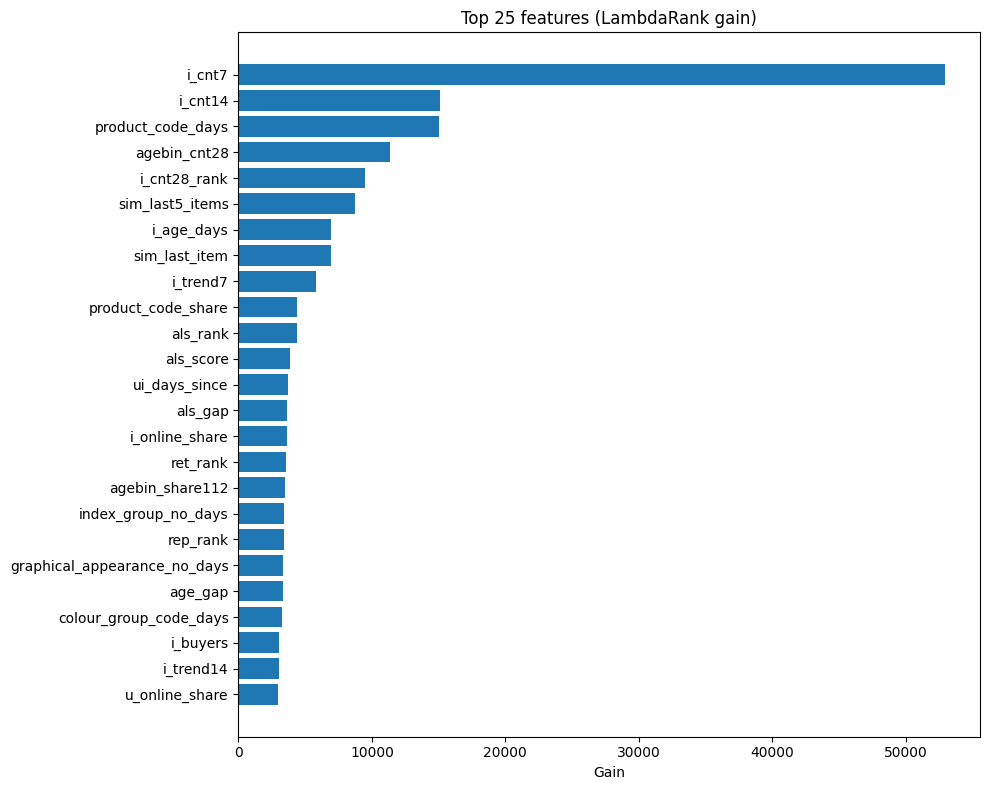

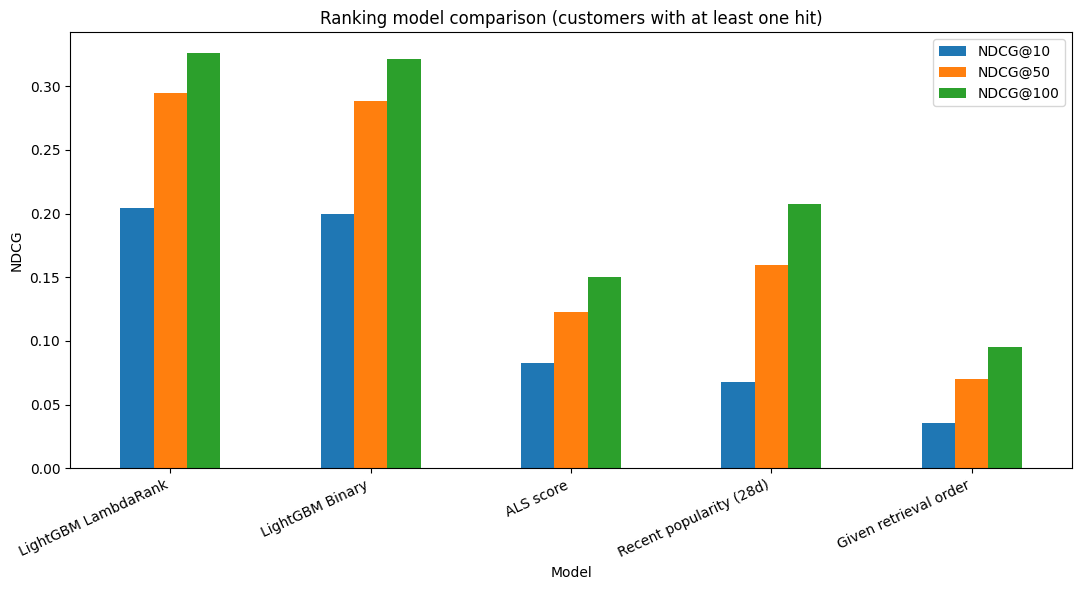

[  675.4s] Saved results to /content/ranking_outputs
['ranked_recommendations.csv', 'model_comparison.csv', 'model_comparison.png', 'feature_importance.png', 'feature_importance.csv']


In [14]:
import matplotlib.pyplot as plt

OUTPUT_DIR = "/content/ranking_outputs" if os.path.isdir("/content") else os.path.join(os.getcwd(), "ranking_outputs")
os.makedirs(OUTPUT_DIR, exist_ok=True)

results_df.to_csv(os.path.join(OUTPUT_DIR, "model_comparison.csv"), index=False)

sort_order = np.lexsort((-rank_scores, test_users_rows))
sorted_users = test_users_rows[sort_order]
sorted_articles = test_articles_rows[sort_order]
sorted_scores = rank_scores[sort_order]
first_of_user = np.concatenate(([True], sorted_users[1:] != sorted_users[:-1]))
group_start = np.maximum.accumulate(np.where(first_of_user, np.arange(len(sorted_users)), 0))
within_user_rank = np.arange(len(sorted_users)) - group_start + 1
keep_rows = within_user_rank <= 100

recommendations = pd.DataFrame({
    "customer_id": customer_index[sorted_users[keep_rows]],
    "article_id": article_index[sorted_articles[keep_rows]],
    "rank": within_user_rank[keep_rows],
    "score": sorted_scores[keep_rows],
})
recommendations.to_csv(os.path.join(OUTPUT_DIR, "ranked_recommendations.csv"), index=False)

importance = pd.Series(
    rank_model.feature_importance(importance_type="gain"), index=feature_names
).sort_values(ascending=False)
importance.to_csv(os.path.join(OUTPUT_DIR, "feature_importance.csv"), header=["gain"])

top_features = importance.head(25).iloc[::-1]
plt.figure(figsize=(10, 8))
plt.barh(top_features.index, top_features.values)
plt.title("Top 25 features (LambdaRank gain)")
plt.xlabel("Gain")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "feature_importance.png"), dpi=120)
plt.show()

comparison = results_df.set_index("Model")[["NDCG@10", "NDCG@50", "NDCG@100"]]
comparison.plot(kind="bar", figsize=(11, 6))
plt.title("Ranking model comparison (customers with at least one hit)")
plt.ylabel("NDCG")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "model_comparison.png"), dpi=120)
plt.show()

log(f"Saved results to {OUTPUT_DIR}")
print(os.listdir(OUTPUT_DIR))

In [17]:
# Show variables related to models and validation data
for name in globals():
    if any(key in name.lower() for key in
           ["model", "binary", "lgb", "valid", "test", "label", "target"]):
        print(name)

lgb
target_files
window_targets
target_keys
total_targets
valid
labels
n_test
n_valid
test_users
valid_users
valid_index
test_index
y_valid
valid_groups
X_test
y_test
test_users_rows
test_articles_rows
rank_model
binary_params
binary_model
binary_scores
model_name


In [19]:
print("binary_model type:", type(binary_model))
print("valid type:", type(valid))
print("valid shape:", getattr(valid, "shape", "No shape"))
print("X_test shape:", getattr(X_test, "shape", "No shape"))

print("Expected features:", binary_model.num_feature())
print("Validation labels:", len(y_valid))

binary_model type: <class 'lightgbm.basic.Booster'>
valid type: <class 'numpy.ndarray'>
valid shape: (246, 100)
X_test shape: (1848140, 85)
Expected features: 85
Validation labels: 279387


In [21]:

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Predict on the held-out test set
y_pred_proba = binary_model.predict(X_test)

# Convert probabilities to binary predictions
y_pred = (y_pred_proba >= 0.5).astype(int)

# Calculate Accuracy
accuracy = accuracy_score(y_test, y_pred)

print(f"Binary Model Accuracy: {accuracy:.4%}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))


Binary Model Accuracy: 99.8958%

Confusion Matrix:
[[1846208      28]
 [   1897       7]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00   1846236
           1       0.20      0.00      0.01      1904

    accuracy                           1.00   1848140
   macro avg       0.60      0.50      0.50   1848140
weighted avg       1.00      1.00      1.00   1848140



In [22]:
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score

# Reuse the probabilities from the Binary Model
y_prob = binary_model.predict(X_test)

for threshold in [0.5, 0.1, 0.05, 0.01, 0.005, 0.001]:
    y_pred = (y_prob >= threshold).astype(int)

    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    print(
        f"Threshold={threshold:.3f} | "
        f"Precision={precision:.4f} | "
        f"Recall={recall:.4f} | "
        f"F1={f1:.4f} | "
        f"Predicted Positives={y_pred.sum()}"
    )

Threshold=0.500 | Precision=0.2000 | Recall=0.0037 | F1=0.0072 | Predicted Positives=35
Threshold=0.100 | Precision=0.0306 | Recall=0.1360 | F1=0.0500 | Predicted Positives=8464
Threshold=0.050 | Precision=0.0158 | Recall=0.2831 | F1=0.0299 | Predicted Positives=34146
Threshold=0.010 | Precision=0.0048 | Recall=0.8025 | F1=0.0096 | Predicted Positives=317546
Threshold=0.005 | Precision=0.0035 | Recall=0.9223 | F1=0.0070 | Predicted Positives=497263
Threshold=0.001 | Precision=0.0022 | Recall=0.9884 | F1=0.0044 | Predicted Positives=860205
